# Import Library & Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)
from sklearn.preprocessing import LabelEncoder

In [3]:
#df_base = pd.read_csv('df_final_merge.csv')
df_base = pd.read_csv('merge_DocLab_balanced.csv')

In [4]:
df_base

,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,1,61.0,169.98,0.40,115.3,220.4,11.0,14.4,25.8,32.4,79.6,100.0,9.9,0
1,0,59.0,111.00,1.68,70.0,193.4,12.0,26.9,25.9,34.0,76.2,100.0,14.7,0
2,1,40.0,166.59,0.78,117.2,70.0,13.1,12.6,28.7,32.8,88.1,46.0,11.9,0
3,1,69.0,218.78,2.50,103.7,161.8,9.4,30.3,20.8,29.7,69.8,10.0,5.8,0
4,1,45.0,222.84,1.22,79.3,217.3,8.2,20.5,26.6,37.0,105.0,100.0,15.9,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7095,0,63.0,140.39,0.88,80.3,215.0,12.5,20.9,26.7,31.2,83.3,26.7,10.4,3
7096,0,62.0,208.22,1.02,159.4,166.0,9.3,14.1,26.7,28.7,82.0,45.6,7.4,3
7097,0,49.0,146.26,0.90,114.5,180.0,11.2,18.7,26.8,33.0,71.0,35.6,8.3,3
7098,0,70.0,190.54,1.19,141.8,142.9,10.2,22.8,26.5,32.2,86.9,35.7,8.1,3


# Feature Engineering

In [5]:
df = df_base.copy()

In [6]:
df['target'] = df['NM_UNIT'].fillna(0).astype(int)

In [8]:
df['target'].value_counts()

,count
target,
0,2100
2,2000
1,1500
3,1500


In [10]:
df['NM_UNIT'].value_counts()

,count
NM_UNIT,
0,2100
2,2000
1,1500
3,1500


# Cleaning

In [ ]:
selected_cols = [
    'creatinin',
    'ureum',
    'glukosa darah sewaktu',
    'kolesterol total',
    'glukosa darah puasa',
    'hgb',
    'mcv',
    'mch',
    'mchc',
    'lymfosit%',
    'wbc'
]

In [ ]:
# Filter kolom yang benar-benar ada
selected_cols = [col for col in selected_cols if col in df.columns]

# Subset
df_subset = df[selected_cols + ['target']].copy()

In [ ]:
# Missing count
missing_count = df_subset.isna().sum()

# Missing percentage
missing_pct = (df_subset.isna().mean() * 100).round(2)

In [ ]:
# Combine
missing_summary = pd.DataFrame({
    'missing_count': missing_count,
    'missing_pct (%)': missing_pct
}).sort_values(by='missing_pct (%)', ascending=False)

print(missing_summary)

# Mutliclass Feature Engineering

In [11]:
df_multiclass = df_base.copy()

In [12]:
# create base target = 0 (normal)
df_multiclass['target'] = 0

# mapping NM_UNIT → label
mapping = {
    'JANTUNG DAN PEMBULUH DARAH': 1,
    'SPES. PENYAKIT DALAM': 2,
    'SPES. PARU PARU': 3
}

In [13]:
# assign label hanya jika ada diagnosa
df_multiclass.loc[df_multiclass['NM_UNIT'].isin(mapping.keys()), 'target'] = df_multiclass['NM_UNIT'].map(mapping)

# drop rows di luar 3 kategori dokter
df_multiclass = df_multiclass[df_multiclass['target'].isin([0,1,2,3])]

In [14]:
# Sanity check
print(df_multiclass['target'].value_counts())

target
0    7100
Name: count, dtype: int64


cek korelasinya

In [15]:
# ambil numeric saja
df_numeric = df_multiclass.select_dtypes(include=['number'])

corr = df_numeric.corr(method='pearson')

target_corr = corr['target'].drop('target').sort_values(
    key=lambda x: x.abs(), ascending=False
)

print(target_corr.head(20))

JENIS_KELAMIN       NaN
UMUR_TAHUN          NaN
cholesterol total   NaN
creatinin           NaN
fbs                 NaN
rbs                 NaN
hgb                 NaN
lymfosit%           NaN
mch                 NaN
mchc                NaN
mcv                 NaN
ureum               NaN
wbc                 NaN
NM_UNIT             NaN
Name: target, dtype: float64


# Correlation

Use fix data

In [17]:
df = pd.read_csv('merge_DocLab_balanced.csv')

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7100 entries, 0 to 7099
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   JENIS_KELAMIN      7100 non-null   int64  
 1   UMUR_TAHUN         7100 non-null   float64
 2   cholesterol total  7100 non-null   float64
 3   creatinin          7100 non-null   float64
 4   fbs                7100 non-null   float64
 5   rbs                7100 non-null   float64
 6   hgb                7100 non-null   float64
 7   lymfosit%          7100 non-null   float64
 8   mch                7100 non-null   float64
 9   mchc               7100 non-null   float64
 10  mcv                7100 non-null   float64
 11  ureum              7100 non-null   float64
 12  wbc                7100 non-null   float64
 13  NM_UNIT            7100 non-null   int64  
dtypes: float64(12), int64(2)
memory usage: 776.7 KB


### Filter Method(Pearson)

cek semua fitur

In [19]:
corr = df.select_dtypes(include=['number']).corr(method='pearson')

In [20]:
target_corr = corr['NM_UNIT'].drop('NM_UNIT').sort_values(
    key=lambda x: x.abs(), ascending=False
)

In [21]:
# Recalculate correlation for the current 'df' (merge_DocLab_synthetic_clean)
corr_recalculated = df.select_dtypes(include=['number']).corr(method='pearson')
target_corr_recalculated = corr_recalculated['NM_UNIT'].drop('NM_UNIT').sort_values(
    key=lambda x: x.abs(), ascending=False
)

print("Korelasi fitur-fitur dengan 'NM_UNIT' (dari merge_DocLab_synthetic_clean):")
display(target_corr_recalculated)

Korelasi fitur-fitur dengan 'NM_UNIT' (dari merge_DocLab_synthetic_clean):


,NM_UNIT
hgb,-0.263653
cholesterol total,-0.169348
lymfosit%,-0.167786
mchc,-0.140871
mch,-0.116908
UMUR_TAHUN,-0.100625
ureum,-0.095064
JENIS_KELAMIN,-0.074391
mcv,-0.049431
rbs,-0.038157


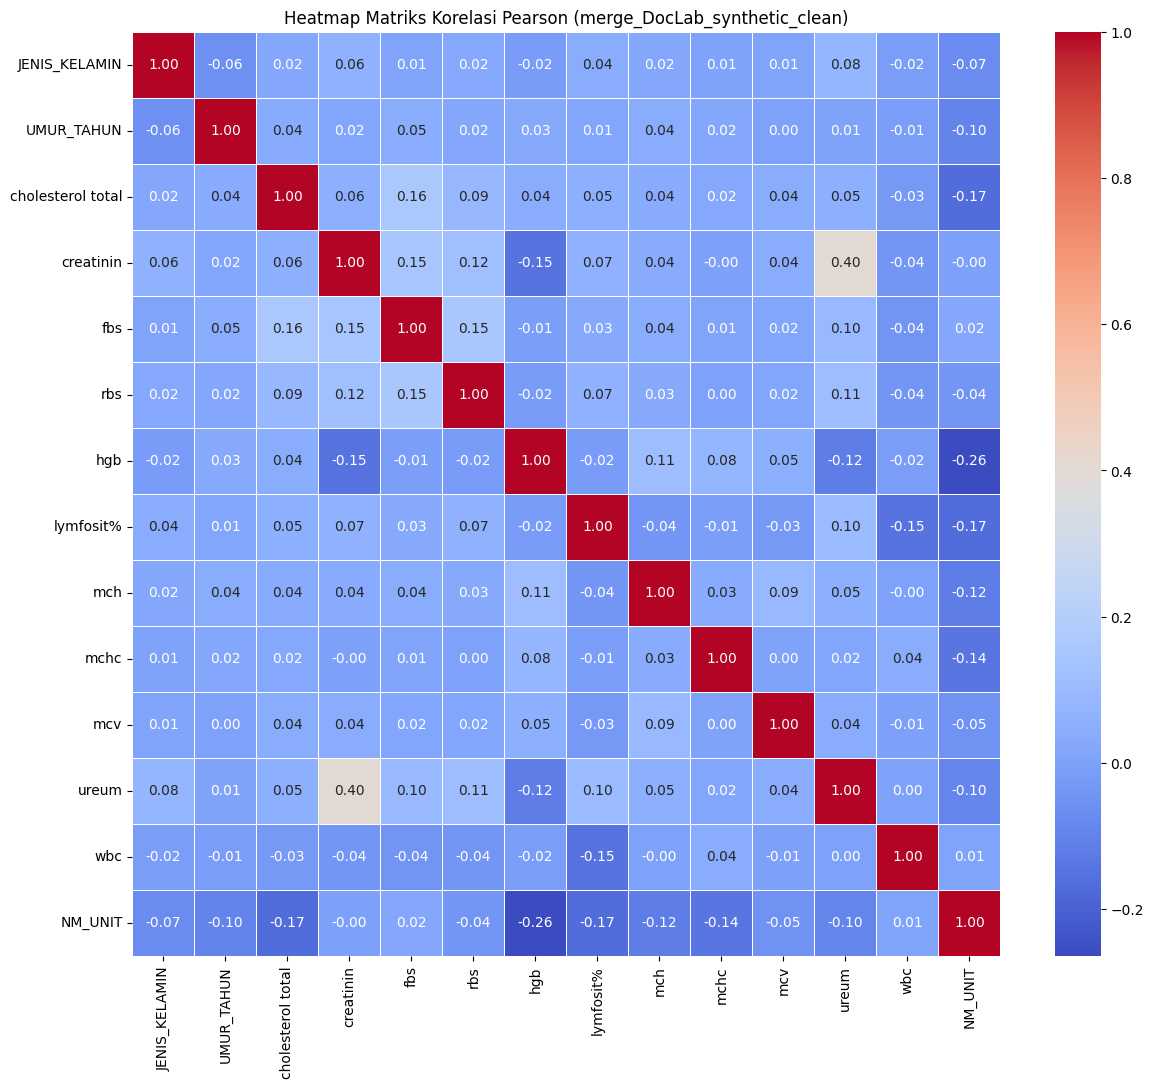

In [22]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr_recalculated, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap Matriks Korelasi Pearson (merge_DocLab_synthetic_clean)')
plt.show()

### Wrapper Method

Forward Selection


In [23]:
def forward_selection(data, target, significance_level=0.05):
    features = data.columns.tolist()
    features.remove(target)

    selected = []

    while True:
        changed = False
        remaining = list(set(features) - set(selected))
        pvals = pd.Series(index=remaining, dtype=float)

        for col in remaining:
            model = sm.OLS(data[target], sm.add_constant(data[selected + [col]])).fit()
            pvals[col] = model.pvalues[col]

        if pvals.empty:
            break

        best_pval = pvals.min()

        if best_pval < significance_level:
            best_feature = pvals.idxmin()
            selected.append(best_feature)
            changed = True

        if not changed:
            break

    return selected

In [24]:
forward_features = forward_selection(df, 'NM_UNIT')

In [25]:
print("\n=== Forward Selection ===")
print(forward_features)


=== Forward Selection ===
['hgb', 'lymfosit%', 'cholesterol total', 'mchc', 'ureum', 'UMUR_TAHUN', 'mch', 'JENIS_KELAMIN', 'fbs', 'mcv']


Backward Elimination

In [26]:
def backward_elimination(data, target, significance_level=0.05):
    features = data.columns.tolist()
    features.remove(target)

    while True:
        model = sm.OLS(data[target], sm.add_constant(data[features])).fit()
        pvals = model.pvalues.drop('const')

        worst_pval = pvals.max()

        if worst_pval > significance_level:
            worst_feature = pvals.idxmax()
            features.remove(worst_feature)
        else:
            break

    return features

In [27]:
backward_features = backward_elimination(df, 'NM_UNIT')

In [28]:
print("\n=== Backward Elimination ===")
print(backward_features)


=== Backward Elimination ===
['JENIS_KELAMIN', 'UMUR_TAHUN', 'cholesterol total', 'fbs', 'hgb', 'lymfosit%', 'mch', 'mchc', 'mcv', 'ureum']


# Modelling

## Build Model

In [29]:
# Fitur final = union forward & backward
final_features = list(set(forward_features + backward_features))
print("\n=== Final Selected Features (union) ===")
print(final_features)


=== Final Selected Features (union) ===
['JENIS_KELAMIN', 'cholesterol total', 'UMUR_TAHUN', 'mcv', 'mch', 'mchc', 'hgb', 'fbs', 'ureum', 'lymfosit%']


In [30]:
X = df[final_features]
y = df['NM_UNIT']

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")


Train: (5680, 10), Test: (1420, 10)


## Training

In [32]:
# --- Model 1: Default ---
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## Evaluation

### Confusion Matrix

In [33]:
print("\n=== Classification Report ===")
print(classification_report(
    y_test, y_pred,
    target_names=['Normal', 'Jantung', 'Peny.Dalam', 'Paru']
))


=== Classification Report ===
              precision    recall  f1-score   support

      Normal       0.85      0.86      0.86       420
     Jantung       0.78      0.80      0.79       300
  Peny.Dalam       0.87      0.78      0.82       400
        Paru       0.83      0.92      0.88       300

    accuracy                           0.84      1420
   macro avg       0.83      0.84      0.84      1420
weighted avg       0.84      0.84      0.84      1420



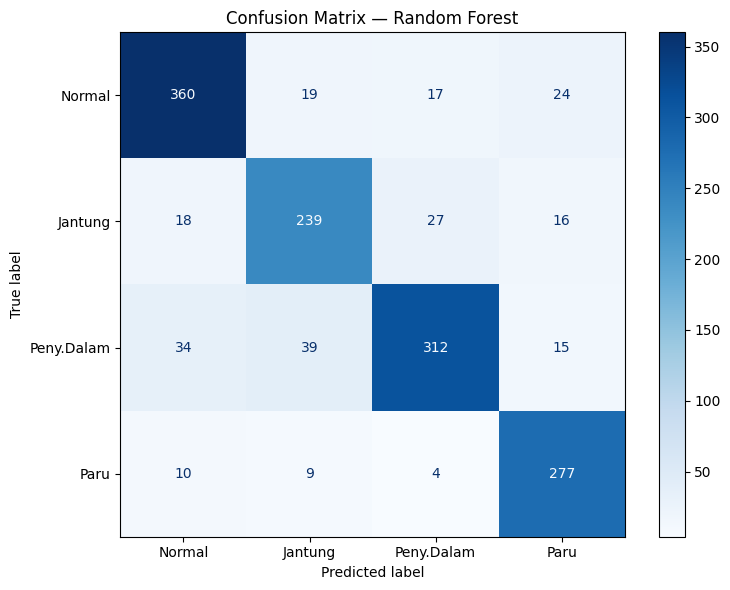

In [34]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Normal', 'Jantung', 'Peny.Dalam', 'Paru'],
    cmap='Blues', ax=ax
)
plt.title('Confusion Matrix — Random Forest')
plt.tight_layout()
plt.show()

### Cross Validation

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_f1  = cross_val_score(rf, X, y, cv=cv, scoring='f1_weighted')
cv_acc = cross_val_score(rf, X, y, cv=cv, scoring='accuracy')

print(f"\nCV F1  (5-fold): {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
print(f"CV Acc (5-fold): {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")


CV F1  (5-fold): 0.8349 ± 0.0090
CV Acc (5-fold): 0.8356 ± 0.0087


### Feature Importance

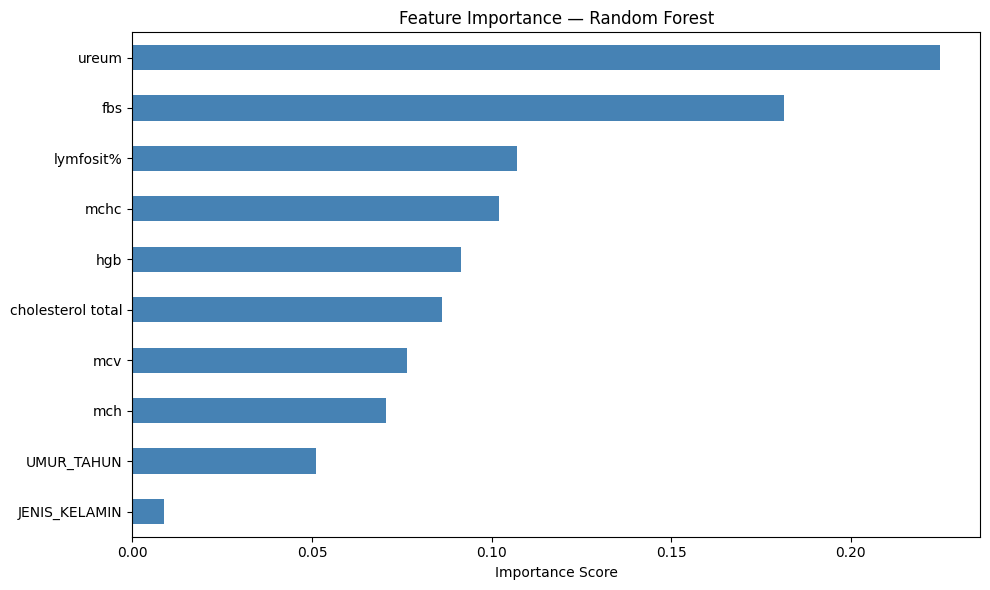


=== Feature Importance ===


,Feature,Importance
0,ureum,0.224705
1,fbs,0.181417
2,lymfosit%,0.107116
3,mchc,0.102143
4,hgb,0.091584
5,cholesterol total,0.086103
6,mcv,0.076374
7,mch,0.070576
8,UMUR_TAHUN,0.051073
9,JENIS_KELAMIN,0.008910


In [36]:
fi = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
fi.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\n=== Feature Importance ===")
display(fi.reset_index().rename(columns={'index': 'Feature', 0: 'Importance'}))